# NAME: PRABHKIRAT SINGH MARWAH 
# SECTION: B
# BATCH: B4
# ROLL NO: 47
# ML LAB 6: PERCEPTRON

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
df = pd.read_csv('seeds_new.csv')

In [ ]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
X = df.drop("Class (1, 2, 3)", axis = 1)
y_original = df['Class (1, 2, 3)']

print("Input Shape: ", X.shape)
print("Output Shape: ", y_original.shape)

Input Shape:  (210, 7)
Output Shape:  (210,)


In [ ]:
y = y_original - 1
print("Original Classes: ")
print(sorted(y_original.unique()))
print("New Classes: ")
print(sorted(y.unique()))

Original Classes: 
[np.int64(1), np.int64(2), np.int64(3)]
New Classes: 
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42, stratify = y)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [ ]:
model = Sequential([
    Input(shape = (7,)),
    Dense(16, activation = 'relu'),
    Dense(8 , activation = 'relu'),
    Dense(3 , activation = 'softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer = Adam(learning_rate=0.001), loss = "sparse_categorical_crossentropy", metrics=['accuracy'])


In [ ]:
loss = "sparse_categorical_crossentropy"


In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)


In [ ]:
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop]
    # ,verbose = True
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9254 - loss: 0.1783 - val_accuracy: 0.9706 - val_loss: 0.1624
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9254 - loss: 0.1769 - val_accuracy: 0.9706 - val_loss: 0.1628
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9254 - loss: 0.1749 - val_accuracy: 0.9706 - val_loss: 0.1645
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9254 - loss: 0.1729 - val_accuracy: 0.9706 - val_loss: 0.1659
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9254 - loss: 0.1709 - val_accuracy: 0.9412 - val_loss: 0.1674
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9254 - loss: 0.1692 - val_accuracy: 0.9118 - val_loss: 0.1686
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9254 - loss: 0.1674 - val_accuracy: 0.9118 - val_loss: 0.1691
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9254 - loss: 0.1664 - val_accuracy: 0.9118 - val_loss:

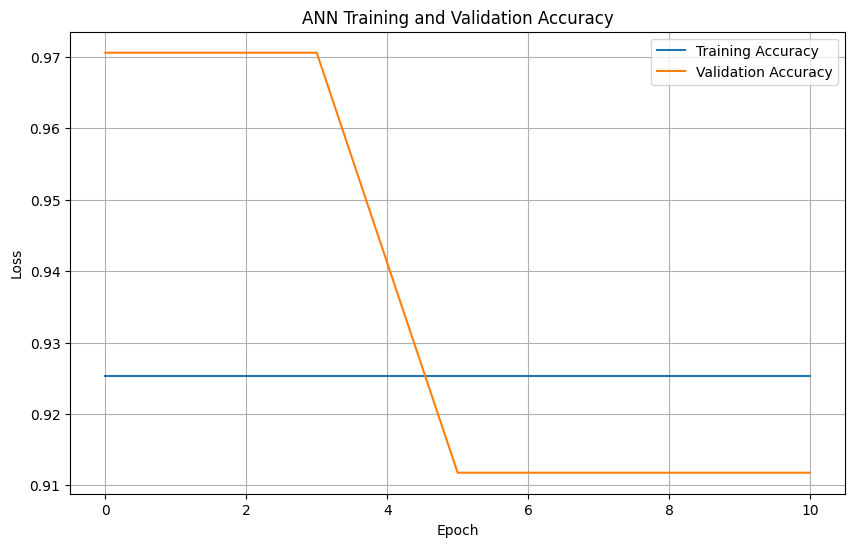

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ANN Training and Validation Accuracy')
plt.legend()
plt.grid(1)
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss * 100:.2f}%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8810 - loss: 0.2555
Test Accuracy: 88.10%
Test Loss: 25.55%


In [ ]:
y_prob = model.predict(X_test_scaled, verbose = True)
print(y_prob[:5])
y_pred = np.argmax(y_prob, axis=1)
print()
print("Predicted encoded Classes: ")
print(y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
[[9.06602085e-01 1.36398012e-02 7.97581598e-02]
 [8.32178071e-02 5.38138382e-04 9.16244030e-01]
 [3.37589771e-01 6.43569052e-01 1.88411493e-02]
 [1.30061265e-02 4.85827286e-06 9.86989021e-01]
 [1.69817377e-02 9.81758296e-01 1.25996128e-03]]

Predicted encoded Classes: 
[0 2 1 2 1 2 1 1 1 1]


In [ ]:
y_pred_original = y_pred+1
y_test_original = y_test+1


In [ ]:
comparision = pd.DataFrame({'Actual Class:': y_test_original.values, 'Predicted Class:': y_pred_original})
comparision.head(10)

,Actual Class:,Predicted Class:
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2
5,3,3
6,2,2
7,1,2
8,2,2
9,2,2


In [ ]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print("Accuracy: ", accuracy)

Accuracy:  0.8809523809523809


In [ ]:
precision = precision_score(y_test_original, y_pred_original, average='weighted')
print("Precision: ", precision)

Precision:  0.8995098039215687


In [ ]:
recall = recall_score(y_test_original, y_pred_original, average='weighted')
print("Recall: ", recall)

Recall:  0.8809523809523809


In [ ]:
f1 = f1_score(y_test_original, y_pred_original, average='weighted')
print("Precision: ", f1)

Precision:  0.8730559451457066


In [ ]:
metrics = pd.DataFrame({'Accuracy': [accuracy], 'Precision': [precision], 'Recall': [recall], 'F1 Score': [f1]})
metrics.head()

,Accuracy,Precision,Recall,F1 Score
0,0.880952,0.89951,0.880952,0.873056


In [ ]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       1.00      0.64      0.78        14
           2       0.82      1.00      0.90        14
           3       0.88      1.00      0.93        14

    accuracy                           0.88        42
   macro avg       0.90      0.88      0.87        42
weighted avg       0.90      0.88      0.87        42



In [ ]:
cm = confusion_matrix(y_test_original, y_pred_original)
print(cm)

[[ 9  3  2]
 [ 0 14  0]
 [ 0  0 14]]


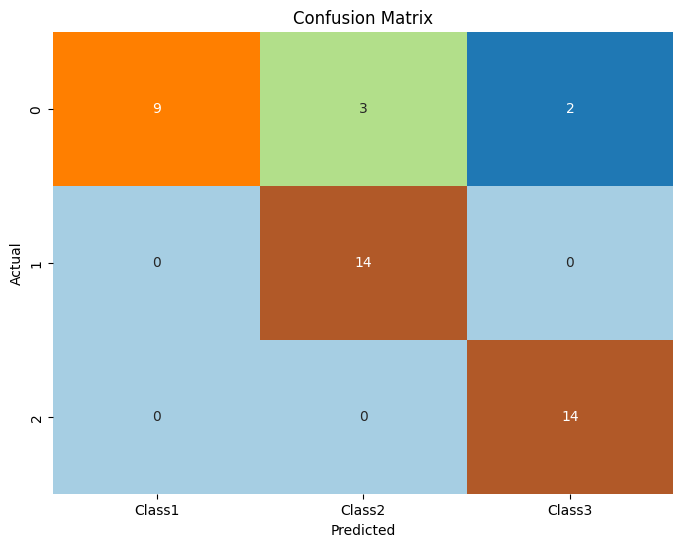

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Paired', xticklabels=["Class1","Class2","Class3"],cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()